# Predicting NFL In-Game Speed from Combine Tracking Data: Target Formulation, Temporal Validation, and the Role of Micro-Biomechanical Features

---

## 1. Problem Formulation and Research Questions

At the NFL Scouting Combine, Wide Receiver (WR) prospects are evaluated both in linear speed drills (the 40-yard dash) and in position-specific route drills (*gauntlet*, *slant*, *out*, *corner*, *post*, *go*) using 10 Hz player-tracking sensors. While traditional scouting relies primarily on stopwatch 40-yard dash times (`forty`) and basic anthropometric measurements (`combine_height`, `combine_weight`), tracking-derived micro-biomechanical metrics from route drills have been proposed to better capture in-game speed and Combine-to-NFL speed translation (*Kinematic Translation Ratio — KTR*).

This study addresses three empirical research questions:
1. **Direct In-Game Speed Prediction:** To what extent can pre-draft Combine measurements predict a WR prospect's regular-season 95th-percentile in-game speed (`nfl_v95`) across unseen draft cohorts?
2. **Incremental Value of Route Micro-Features:** Do Combine route-drill tracking features (`hb_v95`, `deep_v95`, `hb_cut_speed_retention`) and extended sensor speed/acceleration metrics (`s1_v95`, `s2_vmax`, `forty_a95`, `s2_a95`) provide consistent out-of-sample gains over a parsimonious baseline of linear speed and anthropometrics?
3. **Target Formulation (Ratio vs. Numerator Modeling):** When modeling `KTR_Skill_Speed = nfl_v95 / s2_v95`, how much predictive performance stems from learning in-game speed (`nfl_v95`) versus leveraging the known pre-draft Combine denominator (`s2_v95`)?

---

## 2. Dataset, Target Variables, and Feature Engineering

* **Cohort Structure ($N = 76$ WRs):** 2023 Draft Cohort ($N = 31$), 2024 Draft Cohort ($N = 26$), and 2025 Draft Cohort ($N = 19$).
* **Primary Target (`nfl_v95`, yds/s):** 95th-percentile speed across tracked regular-season NFL pass plays.
* **Secondary Ratio Target (`KTR_Skill_Speed`):** $\mathrm{KTR\_Skill\_Speed} = \frac{\mathrm{nfl\_v95}}{\mathrm{s2\_v95}}$, where `s2_v95` is the Combine Stage-2 (route drill) 95th-percentile speed observable prior to the draft.
* **Feature Hygiene:** All model inputs are strictly restricted to pre-draft Combine measurements. Post-draft NFL variables (`reg_plays_tracked`, `starter_ratio`) are excluded from all predictive models and used solely in post-hoc residual diagnostics.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

CACHE_DIR = Path("data_cache")
wr_micro_df = pd.read_parquet(CACHE_DIR / "wr_predraft_micro_master.parquet")
df = wr_micro_df.dropna(subset=["nfl_v95", "s2_v95", "KTR_Skill_Speed", "draft_year"]).copy().reset_index(drop=True)
df["draft_year"] = df["draft_year"].astype(int)

print(f"Sample Size: N = {len(df)} WRs | Cohort Counts: {df['draft_year'].value_counts().sort_index().to_dict()}")

feature_definitions = [
    ("forty_vmax", "40-Yd Sensor Peak Speed (yds/s)"),
    ("forty", "40-Yd Official Stopwatch Time (s)"),
    ("combine_weight", "Combine Body Weight (lb)"),
    ("s1_v95", "Combine Stage-1 Track P95 Speed (yds/s)"),
    ("combine_height", "Combine Height (in)"),
    ("s2_vmax", "Combine Stage-2 Route Peak Speed (yds/s)"),
    ("hb_cut_speed_retention", "Hard-Break Cut Speed Retention (hb_cut_speed / hb_v95)"),
    ("deep_v95", "Deep-Route Drill P95 Speed (yds/s)"),
    ("forty_a95", "40-Yd Sensor P95 Acceleration (yds/s^2)"),
    ("hb_v95", "Hard-Break Route Drill P95 Speed (yds/s)"),
    ("s2_a95", "Combine Stage-2 Route P95 Acceleration (yds/s^2)"),
    ("s2_v95", "Combine Stage-2 Overall Route P95 Speed (KTR Denominator)"),
]

corr_records = []
for col, desc in feature_definitions:
    cols_unique = list(dict.fromkeys([col, "nfl_v95", "s2_v95", "KTR_Skill_Speed"]))
    sub = df[cols_unique].dropna()
    r_nfl, p_nfl = stats.pearsonr(sub[col], sub["nfl_v95"])
    rho_nfl, _ = stats.spearmanr(sub[col], sub["nfl_v95"])
    r_s2, _ = stats.pearsonr(sub[col], sub["s2_v95"])
    r_ktr, p_ktr = stats.pearsonr(sub[col], sub["KTR_Skill_Speed"])
    corr_records.append({
        "Feature": col,
        "Description": desc,
        "N": len(sub),
        "r (nfl_v95)": round(r_nfl, 3),
        "p (nfl_v95)": round(p_nfl, 4),
        "Spearman ρ (nfl_v95)": round(rho_nfl, 3),
        "r (s2_v95 Denom.)": round(r_s2, 3),
        "r (KTR)": round(r_ktr, 3),
        "p (KTR)": round(p_ktr, 4),
    })

corr_df = pd.DataFrame(corr_records)
display(corr_df)


Sample Size: N = 76 WRs | Cohort Counts: {2023: 31, 2024: 26, 2025: 19}


Feature,Description,N,r (nfl_v95),p (nfl_v95),Spearman ρ (nfl_v95),r (s2_v95 Denom.),r (KTR),p (KTR)
forty_vmax,40-Yd Sensor Peak Speed (yds/s),68,0.597,0.0000,0.639,0.138,0.332,0.0057
forty,40-Yd Official Stopwatch Time (s),70,-0.525,0.0000,-0.562,-0.159,-0.261,0.0288
combine_weight,Combine Body Weight (lb),76,-0.493,0.0000,-0.508,-0.132,-0.253,0.0274
s1_v95,Combine Stage-1 Track P95 Speed (yds/s),69,0.414,0.0004,0.630,0.043,0.274,0.0226
combine_height,Combine Height (in),76,-0.316,0.0054,-0.343,-0.191,-0.079,0.4952
s2_vmax,Combine Stage-2 Route Peak Speed (yds/s),76,0.266,0.0202,0.385,0.653,-0.325,0.0041
hb_cut_speed_retention,Hard-Break Cut Speed Retention (hb_cut_speed / hb_v95),76,-0.225,0.0502,-0.208,-0.304,0.066,0.5726
deep_v95,Deep-Route Drill P95 Speed (yds/s),76,0.223,0.0528,0.381,0.669,-0.370,0.0010
forty_a95,40-Yd Sensor P95 Acceleration (yds/s^2),68,-0.086,0.4842,-0.125,0.147,-0.174,0.1548
hb_v95,Hard-Break Route Drill P95 Speed (yds/s),76,0.027,0.8185,-0.019,0.706,-0.533,0.0000


---

## 3. Temporal Validation Protocol: Leave-One-Draft-Year-Out (LOGO)

To evaluate cross-cohort generalization across draft classes without mixing players from the same draft year across training and validation sets, **Leave-One-Draft-Year-Out (LOGO)** serves as our primary evaluation protocol, with 5-Fold CV (`KFold(n_splits=5, shuffle=True, random_state=42)`) reported as a secondary reference.

* **Verified Leak-Free Implementation:** In every LOGO fold, median imputation (`SimpleImputer(strategy="median")`), standardization (`StandardScaler()`), `Ridge(alpha=10.0)` fitting, any inner-loop feature selection (`Model C4`), and the training-mean reference ($ar{y}_{\mathrm{train}}$) are executed **strictly inside each training split (`tr_idx`)** without access to test-year observations (`va_idx`).

---

## 4. Comparison of Models A, B, and C on Direct `nfl_v95` Prediction

We compare the standalone route micro model (`Reduced_3`) against three structured model families on identical LOGO splits:
* **Model A (Baseline — `Classical Full`):** `forty + forty_vmax + combine_height + combine_weight` (4 features)
* **Model B (Combined — `Classical Full + Reduced_3`):** `Model A + hb_v95 + deep_v95 + hb_cut_speed_retention` (7 features)
* **Model C (Extended Sensor Speed/Acceleration):**
  * **C1 (Velocity):** `Model A + s1_v95 + s2_vmax` (6 features)
  * **C2 (Acceleration):** `Model A + forty_a95 + s2_a95` (6 features)
  * **C3 (Velocity + Acceleration):** `Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95` (8 features)
  * **C4 (Nested Training-Set Selection):** `Model A + Top-2 correlated extensions selected strictly within each LOGO training split` (6 features)


In [2]:
BASE_CLASSIC = ["forty", "forty_vmax", "combine_height", "combine_weight"]
REDUCED_3 = ["hb_v95", "deep_v95", "hb_cut_speed_retention"]
EXT_POOL_C = ["s1_v95", "s2_vmax", "forty_amax", "forty_a95", "s2_amax", "s2_a95", "hb_a95", "deep_a95", "hb_cut_speed"]

def evaluate_logo_and_5fold(df, features_or_mode, alpha=10.0, label=""):
    y_nfl = df["nfl_v95"].values
    y_ktr = df["KTR_Skill_Speed"].values
    s2 = df["s2_v95"].values
    groups = df["draft_year"].values

    logo = LeaveOneGroupOut()
    oof_nfl_logo = np.zeros(len(df))
    tr_r2_logo, va_r2_logo = [], []
    yr_nfl_r2, yr_nfl_rho = {}, {}
    yr_ktr_r2, yr_ktr_rho = {}, {}

    for tr, va in logo.split(df, y_nfl, groups):
        yr = int(groups[va][0])
        if features_or_mode == "NESTED_TOP2":
            corrs = []
            for c in EXT_POOL_C:
                sub_tr = df.iloc[tr][[c, "nfl_v95"]].dropna()
                r_val, _ = stats.pearsonr(sub_tr[c], sub_tr["nfl_v95"])
                corrs.append((abs(r_val), c))
            corrs.sort(reverse=True)
            feats = BASE_CLASSIC + [c for _, c in corrs[:2]]
        else:
            feats = list(features_or_mode)

        X_tr, X_va = df.iloc[tr][feats], df.iloc[va][feats]
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(X_tr, y_nfl[tr])

        p_tr = pipe.predict(X_tr)
        p_va = pipe.predict(X_va)
        oof_nfl_logo[va] = p_va

        tr_r2_logo.append(r2_score(y_nfl[tr], p_tr))
        va_r2_logo.append(r2_score(y_nfl[va], p_va))
        yr_nfl_r2[yr] = r2_score(y_nfl[va], p_va)
        yr_nfl_rho[yr] = stats.spearmanr(y_nfl[va], p_va)[0]

        p_ktr = p_va / s2[va]
        yr_ktr_r2[yr] = r2_score(y_ktr[va], p_ktr)
        yr_ktr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr)[0]

    oof_ktr_logo = oof_nfl_logo / s2

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_nfl_5f = np.zeros(len(df))
    va_r2_5f = []
    for tr, va in kf.split(df, y_nfl):
        feats = BASE_CLASSIC + ["s1_v95", "hb_cut_speed"] if features_or_mode == "NESTED_TOP2" else list(features_or_mode)
        pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
        pipe.fit(df.iloc[tr][feats], y_nfl[tr])
        p_va = pipe.predict(df.iloc[va][feats])
        oof_nfl_5f[va] = p_va
        va_r2_5f.append(r2_score(y_nfl[va], p_va))

    q75_true = np.percentile(y_nfl, 75)
    q75_pred = np.percentile(oof_nfl_logo, 75)
    top25_capture = np.mean((oof_nfl_logo >= q75_pred)[y_nfl >= q75_true]) * 100.0

    return {
        "Model": label,
        "LOGO_Train_R2": round(np.mean(tr_r2_logo), 3),
        "LOGO_Val_R2": round(np.mean(va_r2_logo), 3),
        "LOGO_Gap": round(np.mean(tr_r2_logo) - np.mean(va_r2_logo), 3),
        "LOGO_Std": round(np.std(va_r2_logo, ddof=0), 3),
        "LOGO_RMSE": round(np.sqrt(mean_squared_error(y_nfl, oof_nfl_logo)), 4),
        "LOGO_MAE": round(mean_absolute_error(y_nfl, oof_nfl_logo), 4),
        "LOGO_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_logo)[0], 3),
        "Top25_Capture_%": round(top25_capture, 1),
        "2023_R2 (ρ)": f"{yr_nfl_r2[2023]:.3f} ({yr_nfl_rho[2023]:.2f})",
        "2024_R2 (ρ)": f"{yr_nfl_r2[2024]:.3f} ({yr_nfl_rho[2024]:.2f})",
        "2025_R2 (ρ)": f"{yr_nfl_r2[2025]:.3f} ({yr_nfl_rho[2025]:.2f})",
        "5Fold_Val_R2": round(np.mean(va_r2_5f), 3),
        "5Fold_Spearman": round(stats.spearmanr(y_nfl, oof_nfl_5f)[0], 3),
        "DerivedKTR_LOGO_R2": round(np.mean(list(yr_ktr_r2.values())), 3),
        "DerivedKTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_logo)), 4),
        "DerivedKTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_logo), 4),
        "DerivedKTR_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_logo)[0], 3),
        "DerivedKTR_2023": f"{yr_ktr_r2[2023]:.3f} ({yr_ktr_rho[2023]:.2f})",
        "DerivedKTR_2024": f"{yr_ktr_r2[2024]:.3f} ({yr_ktr_rho[2024]:.2f})",
        "DerivedKTR_2025": f"{yr_ktr_r2[2025]:.3f} ({yr_ktr_rho[2025]:.2f})",
        "_oof_nfl_logo": oof_nfl_logo,
        "_oof_ktr_logo": oof_ktr_logo,
    }

model_specs = [
    ("Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)", REDUCED_3),
    ("Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)", BASE_CLASSIC),
    ("Model B — Combined: Model A + Reduced_3", BASE_CLASSIC + REDUCED_3),
    ("Model C1 — Extended (Velocity): Model A + s1_v95 + s2_vmax", BASE_CLASSIC + ["s1_v95", "s2_vmax"]),
    ("Model C2 — Extended (Accel.): Model A + forty_a95 + s2_a95", BASE_CLASSIC + ["forty_a95", "s2_a95"]),
    ("Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95", BASE_CLASSIC + ["s1_v95", "s2_vmax", "forty_a95", "s2_a95"]),
    ("Model C4 — Extended (Nested Top-2 Selected in Training Years)", "NESTED_TOP2"),
]

model_results = {}
comparison_rows = []
for name, spec in model_specs:
    res = evaluate_logo_and_5fold(df, spec, alpha=10.0, label=name)
    model_results[name] = res
    comparison_rows.append(res)

comp_df = pd.DataFrame(comparison_rows)
cols_nfl_table = [
    "Model", "LOGO_Train_R2", "LOGO_Val_R2", "LOGO_Gap", "LOGO_Std",
    "LOGO_RMSE", "LOGO_MAE", "LOGO_Spearman", "Top25_Capture_%",
    "2023_R2 (ρ)", "2024_R2 (ρ)", "2025_R2 (ρ)", "5Fold_Val_R2", "5Fold_Spearman"
]
display(comp_df[cols_nfl_table])


Model,LOGO_Train_R2,LOGO_Val_R2,LOGO_Gap,LOGO_Std,LOGO_RMSE,LOGO_MAE,LOGO_Spearman,Top25_Capture_%,2023_R2 (ρ),2024_R2 (ρ),2025_R2 (ρ),5Fold_Val_R2,5Fold_Spearman
Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret),0.118,0.017,0.101,0.049,0.3473,0.2880,0.227,31.6,-0.023 (0.12),0.087 (0.37),-0.012 (0.27),-0.034,0.195
Model A — Baseline: Classical Full (forty + forty_vmax + height + weight),0.451,0.374,0.077,0.054,0.2771,0.2304,0.638,57.9,0.424 (0.62),0.299 (0.62),0.399 (0.68),0.382,0.655
Model B — Combined: Model A + Reduced_3,0.512,0.386,0.126,0.072,0.2765,0.2276,0.676,57.9,0.354 (0.61),0.319 (0.69),0.486 (0.78),0.384,0.686
Model C1 — Extended (Velocity): Model A + s1_v95 + s2_vmax,0.490,0.372,0.118,0.037,0.2770,0.2269,0.657,52.6,0.421 (0.63),0.332 (0.63),0.361 (0.74),0.321,0.660
Model C2 — Extended (Accel.): Model A + forty_a95 + s2_a95,0.470,0.376,0.094,0.041,0.2769,0.2248,0.651,57.9,0.404 (0.65),0.318 (0.64),0.406 (0.74),0.357,0.635
Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95,0.513,0.392,0.121,0.026,0.2727,0.2161,0.683,63.2,0.427 (0.66),0.366 (0.66),0.382 (0.75),0.306,0.642
Model C4 — Extended (Nested Top-2 Selected in Training Years),0.510,0.346,0.165,0.012,0.2839,0.2333,0.666,52.6,0.333 (0.61),0.343 (0.68),0.361 (0.74),0.351,0.692


### Key Analytical Takeaways (Section 4)
* **Standalone Route Micro-Features (`Reduced_3`) Do Not Predict `nfl_v95`:** Used in isolation, `Reduced_3` yields `LOGO R² = 0.017` (`RMSE = 0.3473 yds/s`, `Spearman ρ = 0.227`) and negative $R^2$ in two of the three draft cohorts.
* **Trade-off Between `Model A`, `Model B`, and `Model C3`:** `Model C3` achieves the highest overall LOGO validation metrics (`LOGO R² = 0.392`, `RMSE = 0.2727 yds/s`, `Spearman ρ = 0.683`), while `Model B` achieves `LOGO R² = 0.386` (`ρ = 0.676`). However, `Model A` (`LOGO R² = 0.374`, `RMSE = 0.2771 yds/s`, `ρ = 0.638`) uses only 4 features and maintains the smallest Train–Validation gap (`0.077` vs. `0.121` for `C3` and `0.126` for `B`). Selecting `Model A` as the primary baseline is therefore a **parsimony–performance trade-off** rather than a claim of raw metric superiority.

---

## 5. Denominator Coupling in KTR and the Derived Ratio Approach

To evaluate why `Reduced_3` achieved `LOGO R² = 0.317` when predicting `KTR_Skill_Speed` directly despite having near-zero predictive power for `nfl_v95` (`LOGO R² = 0.017`), we compare direct KTR regression against the **Derived KTR** approach ($\widehat{\mathrm{KTR}} = \widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$) and a **Constant-Mean Numerator Reference** ($\widehat{\mathrm{KTR}}_{\mathrm{ref}} = \bar{y}_{\mathrm{train}} / \mathrm{s2\_v95}$):


In [3]:
logo = LeaveOneGroupOut()
y_nfl = df["nfl_v95"].values
y_ktr = df["KTR_Skill_Speed"].values
s2 = df["s2_v95"].values
groups = df["draft_year"].values

oof_nfl_const = np.zeros(len(df))
const_ktr_yr_r2, const_ktr_yr_rho = {}, {}
for tr, va in logo.split(df, y_nfl, groups):
    yr = int(groups[va][0])
    oof_nfl_const[va] = y_nfl[tr].mean()
    p_ktr_c = oof_nfl_const[va] / s2[va]
    const_ktr_yr_r2[yr] = r2_score(y_ktr[va], p_ktr_c)
    const_ktr_yr_rho[yr] = stats.spearmanr(y_ktr[va], p_ktr_c)[0]
oof_ktr_const = oof_nfl_const / s2

oof_ktr_dir_A = np.zeros(len(df))
oof_ktr_dir_R3 = np.zeros(len(df))
dirA_yr_r2, dirA_yr_rho = {}, {}
dirR3_yr_r2, dirR3_yr_rho = {}, {}

for tr, va in logo.split(df, y_ktr, groups):
    yr = int(groups[va][0])
    pA = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    pA.fit(df.iloc[tr][BASE_CLASSIC], y_ktr[tr])
    oof_ktr_dir_A[va] = pA.predict(df.iloc[va][BASE_CLASSIC])
    dirA_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_dir_A[va])
    dirA_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_dir_A[va])[0]

    pR3 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
    pR3.fit(df.iloc[tr][REDUCED_3], y_ktr[tr])
    oof_ktr_dir_R3[va] = pR3.predict(df.iloc[va][REDUCED_3])
    dirR3_yr_r2[yr] = r2_score(y_ktr[va], oof_ktr_dir_R3[va])
    dirR3_yr_rho[yr] = stats.spearmanr(y_ktr[va], oof_ktr_dir_R3[va])[0]

ktr_rows = [
    {
        "KTR Estimation Strategy": "0. Constant-Mean Numerator Ref. (mean_train_nfl / s2_v95)",
        "Numerator_LOGO_R2": -0.010,
        "KTR_LOGO_Val_R2": round(np.mean(list(const_ktr_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_const)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_const), 4),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_const)[0], 3),
        "2023_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2023]:.3f} ({const_ktr_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2024]:.3f} ({const_ktr_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{const_ktr_yr_r2[2025]:.3f} ({const_ktr_yr_rho[2025]:.2f})",
    },
    {
        "KTR Estimation Strategy": "1. Direct KTR Regression — Model A (Classical Full)",
        "Numerator_LOGO_R2": 0.374,
        "KTR_LOGO_Val_R2": round(np.mean(list(dirA_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_dir_A)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_dir_A)),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_dir_A)[0], 3),
        "2023_KTR_R2 (ρ)": f"{dirA_yr_r2[2023]:.3f} ({dirA_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{dirA_yr_r2[2024]:.3f} ({dirA_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{dirA_yr_r2[2025]:.3f} ({dirA_yr_rho[2025]:.2f})",
    },
    {
        "KTR Estimation Strategy": "2. Direct KTR Regression — Micro Reduced_3",
        "Numerator_LOGO_R2": 0.017,
        "KTR_LOGO_Val_R2": round(np.mean(list(dirR3_yr_r2.values())), 3),
        "KTR_LOGO_RMSE": round(np.sqrt(mean_squared_error(y_ktr, oof_ktr_dir_R3)), 4),
        "KTR_LOGO_MAE": round(mean_absolute_error(y_ktr, oof_ktr_dir_R3), 4),
        "KTR_LOGO_Spearman": round(stats.spearmanr(y_ktr, oof_ktr_dir_R3)[0], 3),
        "2023_KTR_R2 (ρ)": f"{dirR3_yr_r2[2023]:.3f} ({dirR3_yr_rho[2023]:.2f})",
        "2024_KTR_R2 (ρ)": f"{dirR3_yr_r2[2024]:.3f} ({dirR3_yr_rho[2024]:.2f})",
        "2025_KTR_R2 (ρ)": f"{dirR3_yr_r2[2025]:.3f} ({dirR3_yr_rho[2025]:.2f})",
    },
    {
        "KTR Estimation Strategy": "3. Derived KTR (hat_nfl_v95 / s2_v95) — Micro Reduced_3",
        "Numerator_LOGO_R2": 0.017,
        "KTR_LOGO_Val_R2": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_LOGO_RMSE"],
        "KTR_LOGO_MAE": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_LOGO_MAE"],
        "KTR_LOGO_Spearman": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": model_results["Micro Only: Reduced_3 (hb_v95 + deep_v95 + hb_cut_ret)"]["DerivedKTR_2025"],
    },
    {
        "KTR Estimation Strategy": "4. Derived KTR (hat_nfl_v95 / s2_v95) — Model A (Classical Full)",
        "Numerator_LOGO_R2": 0.374,
        "KTR_LOGO_Val_R2": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_LOGO_RMSE"],
        "KTR_LOGO_MAE": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_LOGO_MAE"],
        "KTR_LOGO_Spearman": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["DerivedKTR_2025"],
    },
    {
        "KTR Estimation Strategy": "5. Derived KTR (hat_nfl_v95 / s2_v95) — Model C3 (Extended Vel.+Accel.)",
        "Numerator_LOGO_R2": 0.392,
        "KTR_LOGO_Val_R2": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_LOGO_R2"],
        "KTR_LOGO_RMSE": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_LOGO_RMSE"],
        "KTR_LOGO_MAE": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_LOGO_MAE"],
        "KTR_LOGO_Spearman": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_Spearman"],
        "2023_KTR_R2 (ρ)": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_2023"],
        "2024_KTR_R2 (ρ)": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_2024"],
        "2025_KTR_R2 (ρ)": model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["DerivedKTR_2025"],
    },
]
display(pd.DataFrame(ktr_rows))


KTR Estimation Strategy,Numerator_LOGO_R2,KTR_LOGO_Val_R2,KTR_LOGO_RMSE,KTR_LOGO_MAE,KTR_LOGO_Spearman,2023_KTR_R2 (ρ),2024_KTR_R2 (ρ),2025_KTR_R2 (ρ)
0. Constant-Mean Numerator Ref. (mean_train_nfl / s2_v95),-0.010,0.459,0.0385,0.0325,0.620,0.483 (0.66),0.412 (0.47),0.481 (0.62)
1. Direct KTR Regression — Model A (Classical Full),0.374,0.006,0.0521,0.0000,0.283,0.066 (0.48),-0.025 (0.28),-0.022 (0.34)
2. Direct KTR Regression — Micro Reduced_3,0.017,0.317,0.0438,0.0369,0.472,0.236 (0.46),0.195 (0.25),0.519 (0.64)
3. Derived KTR (hat_nfl_v95 / s2_v95) — Micro Reduced_3,0.017,0.479,0.0379,0.0314,0.645,0.473 (0.66),0.473 (0.54),0.490 (0.70)
4. Derived KTR (hat_nfl_v95 / s2_v95) — Model A (Classical Full),0.374,0.663,0.0303,0.0252,0.773,0.702 (0.80),0.586 (0.67),0.702 (0.75)
5. Derived KTR (hat_nfl_v95 / s2_v95) — Model C3 (Extended Vel.+Accel.),0.392,0.673,0.0299,0.0236,0.800,0.703 (0.82),0.627 (0.71),0.689 (0.85)


### Interpretation of Denominator Coupling and Derived KTR
* **Signal Carried by the Player-Specific Denominator (`s2_v95`):** The constant-mean numerator reference demonstrates that the player-specific Combine `s2_v95` value carries a strong baseline signal in KTR estimation, achieving `LOGO R² = 0.459` and `Spearman ρ = 0.620`.
* **Joint Effect in Derived KTR (`R² = 0.663` for `Model A`, `0.673` for `Model C3`):** Predicting `nfl_v95` out-of-sample via `Model A` (`LOGO R² = 0.374`) and dividing by known `s2_v95` raises KTR `LOGO R²` from `0.459` to `0.663` (`Spearman ρ = 0.773`). This improvement reflects the **joint outcome of out-of-sample `nfl_v95` prediction and the ratio transformation with known `s2_v95`**, rather than evidence that the model has directly learned biomechanical skill transfer.

---

## 6. Player-Level Residual Analysis: Walker, Burton, and Coleman

All 2024 player predictions below are strictly out-of-sample LOGO predictions generated by models trained exclusively on the 2023 and 2025 cohorts ($N = 50$):


display_name,forty,forty_vmax,combine_weight,s2_v95,reg_plays_tracked,nfl_v95,Rank_NFL,Pred_A,Res_A,Rank_A,Pred_B,Res_B,Rank_B,Pred_C3,Res_C3,Rank_C3,Rank_KTR,Rank_KTR_Dir_R3,Rank_KTR_Der_A
Devontez Walker,4.36,11.313,193,9.245,80.0,9.746,1,9.171,0.575,6,9.218,0.528,5,9.223,0.523,5,3,17,11
Jermaine Burton,4.45,11.360,196,9.469,96.0,9.658,2,9.103,0.554,9,9.138,0.519,10,9.101,0.557,10,6,23,20
Troy Franklin,4.41,11.390,176,9.486,742.0,9.440,4,9.296,0.144,3,9.262,0.178,4,9.255,0.185,1,10,25,17
Brian Thomas,4.33,11.547,209,9.099,984.0,9.190,9,9.102,0.088,11,9.156,0.034,7,9.149,0.041,7,8,15,8
Keon Coleman,4.61,10.700,213,9.440,633.0,8.708,22,8.673,0.035,25,8.748,-0.040,25,8.728,-0.020,25,24,5,25


Subgroup,Model_A_OOF_R2,Model_A_RMSE,Model_A_MAE,Model_A_Spearman
"Low Play Volume (<200 plays, N=20)",0.317,0.3605,0.3202,0.497
"Regular Rotation (>=200 plays, N=56)",0.428,0.2317,0.1915,0.633


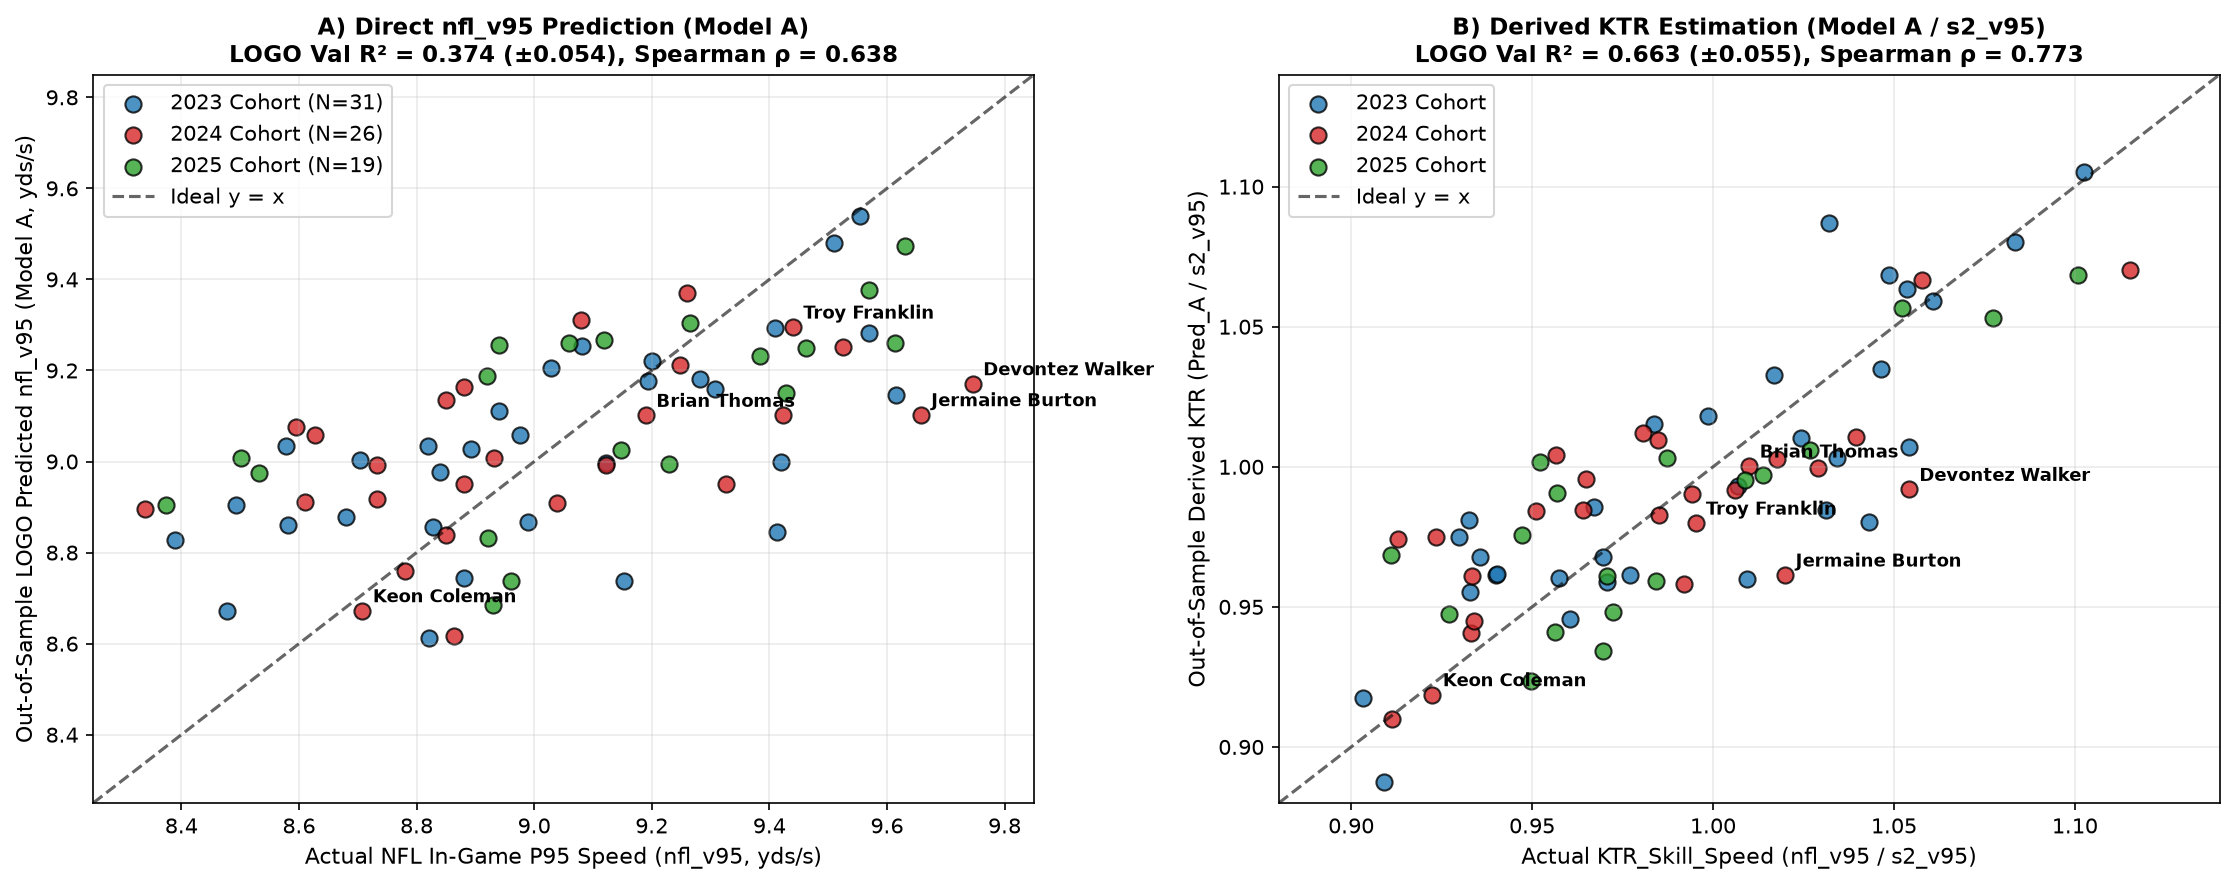

In [4]:
df["Pred_A"] = model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["_oof_nfl_logo"]
df["Pred_B"] = model_results["Model B — Combined: Model A + Reduced_3"]["_oof_nfl_logo"]
df["Pred_C3"] = model_results["Model C3 — Extended (Vel. + Accel.): Model A + s1_v95 + s2_vmax + forty_a95 + s2_a95"]["_oof_nfl_logo"]
df["Pred_KTR_Derived_A"] = model_results["Model A — Baseline: Classical Full (forty + forty_vmax + height + weight)"]["_oof_ktr_logo"]
df["Pred_KTR_Direct_R3"] = oof_ktr_dir_R3

for col_p, col_r in [
    ("nfl_v95", "Rank_NFL"), ("Pred_A", "Rank_A"), ("Pred_B", "Rank_B"), ("Pred_C3", "Rank_C3"),
    ("KTR_Skill_Speed", "Rank_KTR"), ("Pred_KTR_Direct_R3", "Rank_KTR_Dir_R3"), ("Pred_KTR_Derived_A", "Rank_KTR_Der_A")
]:
    df[col_r] = df.groupby("draft_year")[col_p].rank(ascending=False, method="min").astype(int)

df["Res_A"] = df["nfl_v95"] - df["Pred_A"]
df["Res_B"] = df["nfl_v95"] - df["Pred_B"]
df["Res_C3"] = df["nfl_v95"] - df["Pred_C3"]

focus_2024 = ["Devontez Walker", "Jermaine Burton", "Troy Franklin", "Brian Thomas", "Keon Coleman"]
sub24 = df[(df["draft_year"] == 2024) & (df["display_name"].isin(focus_2024))].sort_values("nfl_v95", ascending=False)
display(sub24[[
    "display_name", "forty", "forty_vmax", "combine_weight", "s2_v95", "reg_plays_tracked",
    "nfl_v95", "Rank_NFL", "Pred_A", "Res_A", "Rank_A", "Pred_B", "Res_B", "Rank_B",
    "Pred_C3", "Res_C3", "Rank_C3", "Rank_KTR", "Rank_KTR_Dir_R3", "Rank_KTR_Der_A"
]].round(3))

# Play-Volume Subgroup Error Summary (Descriptive Diagnostic Only)
vol_rows = []
for grp_label, mask in [("Low Play Volume (<200 plays, N=20)", df["reg_plays_tracked"] < 200),
                        ("Regular Rotation (>=200 plays, N=56)", df["reg_plays_tracked"] >= 200)]:
    sub_v = df[mask]
    vol_rows.append({
        "Subgroup": grp_label,
        "Model_A_OOF_R2": round(r2_score(sub_v["nfl_v95"], sub_v["Pred_A"]), 3),
        "Model_A_RMSE": round(np.sqrt(mean_squared_error(sub_v["nfl_v95"], sub_v["Pred_A"])), 4),
        "Model_A_MAE": round(mean_absolute_error(sub_v["nfl_v95"], sub_v["Pred_A"]), 4),
        "Model_A_Spearman": round(stats.spearmanr(sub_v["nfl_v95"], sub_v["Pred_A"])[0], 3),
    })
display(pd.DataFrame(vol_rows))

# Two-Panel Summary Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = {2023: "#1f77b4", 2024: "#d62728", 2025: "#2ca02c"}

# Panel A: Direct nfl_v95 Actual vs Out-of-Sample Predicted (Model A)
for yr, grp in df.groupby("draft_year"):
    axes[0].scatter(grp["nfl_v95"], grp["Pred_A"], label=f"{yr} Cohort (N={len(grp)})", color=colors[yr], s=60, alpha=0.8, edgecolor="k")
lims = [8.25, 9.85]
axes[0].plot(lims, lims, "k--", alpha=0.6, label="Ideal y = x")
for _, r in sub24.iterrows():
    axes[0].annotate(r["display_name"], (r["nfl_v95"], r["Pred_A"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual NFL In-Game P95 Speed (nfl_v95, yds/s)", fontsize=10.5)
axes[0].set_ylabel("Out-of-Sample LOGO Predicted nfl_v95 (Model A, yds/s)", fontsize=10.5)
axes[0].set_title("A) Direct nfl_v95 Prediction (Model A)\nLOGO Val R² = 0.374 (±0.054), Spearman ρ = 0.638", fontsize=11, fontweight="bold")
axes[0].legend(loc="upper left", frameon=True)
axes[0].grid(alpha=0.25)

# Panel B: Derived KTR Actual vs Out-of-Sample Predicted (Model A / s2_v95)
for yr, grp in df.groupby("draft_year"):
    axes[1].scatter(grp["KTR_Skill_Speed"], grp["Pred_KTR_Derived_A"], label=f"{yr} Cohort", color=colors[yr], s=60, alpha=0.8, edgecolor="k")
lims_k = [0.88, 1.14]
axes[1].plot(lims_k, lims_k, "k--", alpha=0.6, label="Ideal y = x")
for _, r in sub24.iterrows():
    axes[1].annotate(r["display_name"], (r["KTR_Skill_Speed"], r["Pred_KTR_Derived_A"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold")
axes[1].set_xlim(lims_k); axes[1].set_ylim(lims_k)
axes[1].set_xlabel("Actual KTR_Skill_Speed (nfl_v95 / s2_v95)", fontsize=10.5)
axes[1].set_ylabel("Out-of-Sample Derived KTR (Pred_A / s2_v95)", fontsize=10.5)
axes[1].set_title("B) Derived KTR Estimation (Model A / s2_v95)\nLOGO Val R² = 0.663 (±0.055), Spearman ρ = 0.773", fontsize=11, fontweight="bold")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


### Diagnostic Findings on Player Residuals
* **Accurate Calibration on High-Volume Starters (`Keon Coleman`, `Brian Thomas`, `Troy Franklin`):** Modeling `nfl_v95` directly resolves the 2024 ranking inversion for `Keon Coleman` (`8.673 yds/s`, residual `+0.035 yds/s`, rank #25/26 in `Model A`, and #25/26 in `Derived KTR` vs. #24/26 actual).
* **Play-Volume Stratification as an Explanatory Hypothesis (`Devontez Walker` and `Jermaine Burton`):** Across all 76 WRs, players with `<200` tracked regular-season plays ($N = 20$, including `Walker` [80 plays] and `Burton` [96 plays]) exhibit higher out-of-sample error (`RMSE = 0.3605 yds/s`) than WRs with $\ge 200$ tracked plays ($N = 56$, `RMSE = 0.2317 yds/s`, `R² = 0.428`). While this pattern suggests that low-snap players may experience greater 95th-percentile sampling variance or specialized vertical route deployment, **low play volume (`reg_plays_tracked`) alone does not prove that a player was deployed exclusively on deep routes**. Testing that mechanism directly requires play-level route classification, target depth (*air yards*), and defensive coverage context beyond pre-draft Combine measurements.

---

## 7. Generalizability, Limitations, and Potential Biases

1. **Limited Cohort Horizon ($N = 76$, Three Draft Classes):** Reported LOGO metrics (`R² = 0.374` for `Model A`; `0.392` for `Model C3`) summarize temporal validation within the 2023–2025 classes and should not be interpreted as guaranteed performance bounds for future seasons.
2. **Sample Selection Bias:** The sample includes only WRs who both participated in Combine tracking drills and logged regular-season NFL routes.
3. **Regularization Shrinkage at the Extremes:** `Ridge(alpha=10.0)` stabilizes out-of-sample variance on small $N$ by shrinking predictions toward the cohort mean (`~8.65–9.35 yds/s`), systematically underpredicting extreme tail observations (`nfl_v95 > 9.60 yds/s`).
4. **Iterative Model Exploration Optimism:** Because candidate feature subsets and model specifications were compared across the same 2023–2025 cohorts, definitive validation requires an untouched future cohort (e.g., the 2026 draft class).

---

## 8. Final Model Decision and Executive Summary

1. **Primary Baseline Model (`Model A — Classical Full`):** `Ridge(alpha=10.0)` with `["forty", "forty_vmax", "combine_height", "combine_weight"]` (`LOGO Val R² = 0.374 ± 0.054`, `Train–Val Gap = 0.077`, `RMSE = 0.2771 yds/s`, `Spearman ρ = 0.638`), selected for its favorable balance between parsimony (4 features) and a small generalization gap.
2. **Complementary Alternatives (`Model B` and `Model C3`):** `Model C3` (`LOGO Val R² = 0.392 ± 0.026`, `RMSE = 0.2727 yds/s`, `Spearman ρ = 0.683`) and `Model B` (`Val R² = 0.386`, `ρ = 0.676`) provide modest out-of-sample gains (`+0.012` to `+0.018 R²`) at the cost of higher dimensionality (7–8 features) and wider Train–Validation gaps (`0.121–0.126`).
3. **Recommended KTR Estimation Protocol:** Estimate $\widehat{\mathrm{nfl\_v95}}$ out-of-sample first and divide by the known Combine `s2_v95` ($\widehat{\mathrm{KTR}} = \widehat{\mathrm{nfl\_v95}} / \mathrm{s2\_v95}$), yielding `LOGO R² = 0.663` (`Spearman ρ = 0.773`) with `Model A` and `0.673` (`ρ = 0.800`) with `Model C3` as the joint outcome of out-of-sample `nfl_v95` prediction and the ratio transformation.
4. **Core Conclusion:** The utility of Combine micro-biomechanical tracking features depends critically on the target variable. For predicting regular-season 95th-percentile speed (`nfl_v95`), the primary predictive signals utilized by the model are linear speed measurements (`forty`, `forty_vmax`) and anthropometric attributes (`combine_weight`, `combine_height`), whereas standalone route-drill speeds (`hb_v95`, `deep_v95`) primarily reflect variations in the Combine denominator (`s2_v95`).
